<a href="https://colab.research.google.com/github/bhavya5646/Experiment-1/blob/main/AI_Yield_Advisor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!unzip -q AX7_SOC_synthetic_chip_test_dataset.zip -d data

In [ ]:
!python 01_data_foundation.py --data data --out clean

== Data quality gates ==
[PASS] no duplicate first-pass die 0 duplicates
[PASS] passing die have all 10 test values 0 blanks
[PASS] single program revision 0 rows differ
[PASS] ECID unique in final test 
[PASS] good-die count reconciles with wafer_summary (0 mismatches)
[PASS] every final-test die passed sort (0 violations)

Saved to clean/: die_final (500,000 rows), die_first_pass, wafer_table (1000 rows)
Final yield 0.8934 | first-pass yield 0.8915


In [ ]:
!python 02_excursion_detector.py --clean clean --fig figures


== Lot sort yield (%): baseline 91.42, sigma 1.62
  Shewhart alarms on 12 lots; episodes: [('L262218', 'L262220'), ('L262226', 'L262231'), ('L262234', 'L262238')]
  EWMA     alarms on  9 lots; episodes: [('L262218', 'L262220'), ('L262227', 'L262231'), ('L262238', 'L262238')]
  CUSUM    alarms on  6 lots; episodes: [('L262218', 'L262220'), ('L262227', 'L262231'), ('L262238', 'L262238')]

== WAT Vt_n (mV): baseline 312.03, sigma 0.48
  Shewhart alarms on  6 lots; episodes: [('L262226', 'L262231')]
  EWMA     alarms on  6 lots; episodes: [('L262226', 'L262231')]
  CUSUM    alarms on  6 lots; episodes: [('L262226', 'L262231')]

== VMIN+FMAX bin loss (% of die): baseline 0.07, sigma 0.03
  Shewhart alarms on  6 lots; episodes: [('L262226', 'L262231')]
  EWMA     alarms on  6 lots; episodes: [('L262226', 'L262231')]
  CUSUM    alarms on  6 lots; episodes: [('L262226', 'L262231')]

== Diagnosis of yield episodes (rise in bin share, percentage points) ==
  L262218-L262220: SB3 +7.26, SB9 +0.5

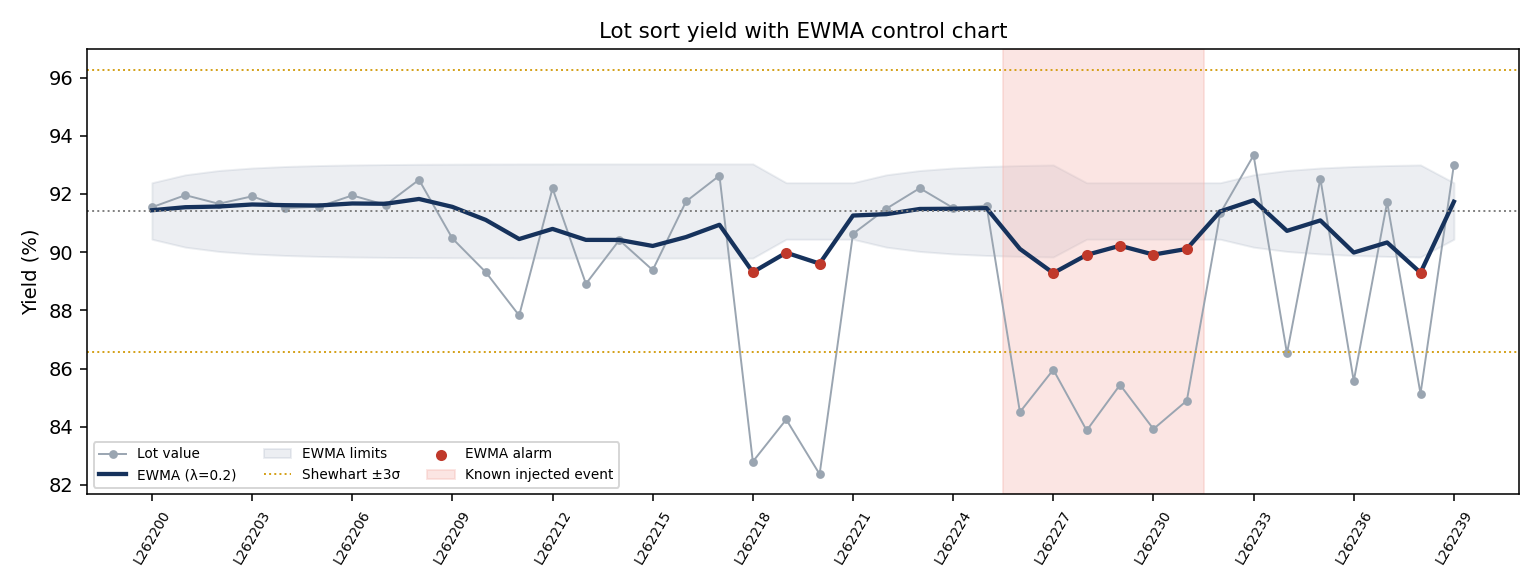

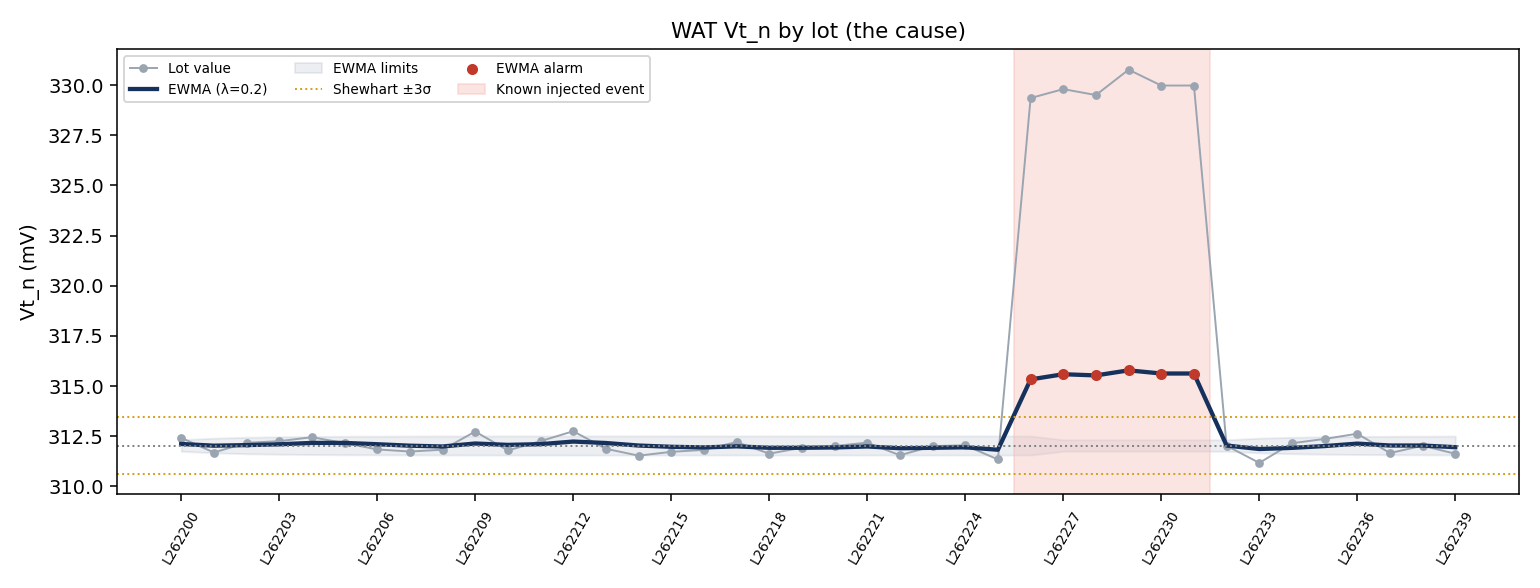

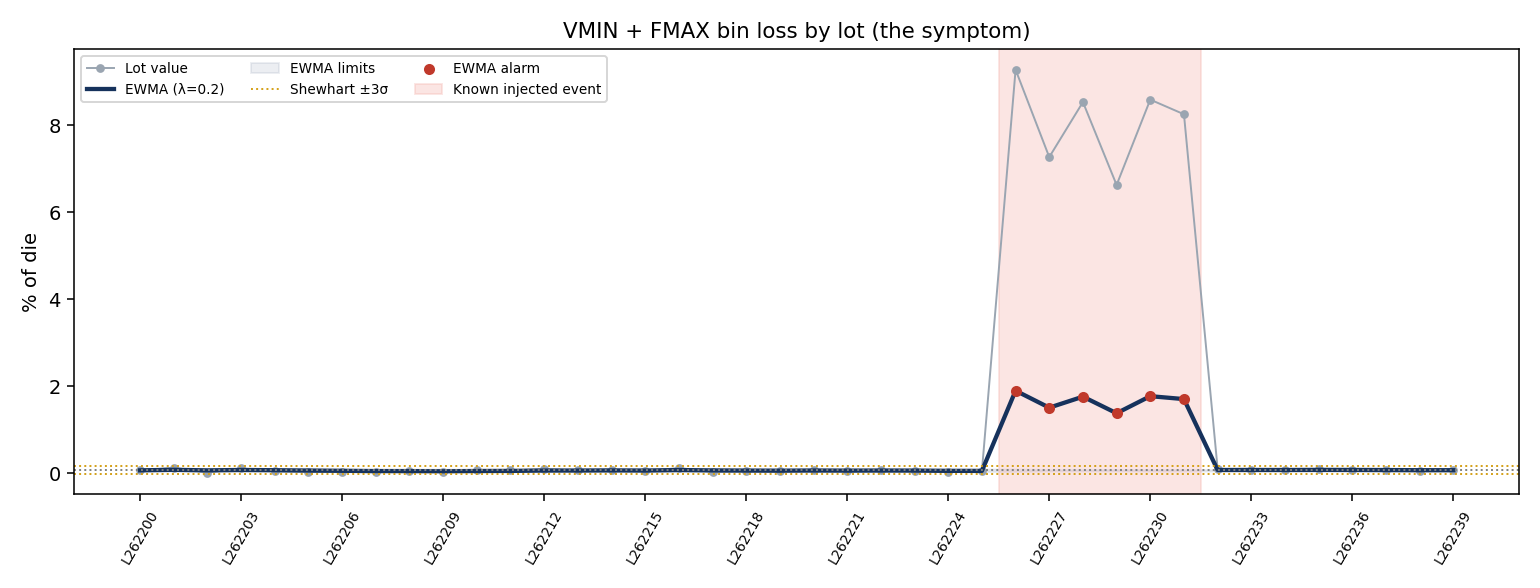

In [ ]:
from IPython.display import Image, display
for f in ["yield_ewma", "vt_ewma", "vmin_fmax_ewma"]:
       display(Image(f"figures/{f}.png"))

In [ ]:
!python 03_root_cause.py --clean clean --data data

Signature wafers flagged: edge-ring 15, center 76, reticle-repeat 75  (of 1000)

== NAIVE: Kruskal-Wallis of wafer yield by tool (no signature matching) ==
  ETCH_tool   p=6.6e-06  means={'ETCH-05': 0.898, 'ETCH-06': 0.908, 'ETCH-07': 0.876, 'ETCH-08': 0.894}
  CMP_tool    p=2.7e-09  means={'CMP-01': 0.88, 'CMP-02': 0.91, 'CMP-03': 0.896}
  LITHO_tool  p=5.2e-02  means={'LIT-01': 0.892, 'LIT-02': 0.892, 'LIT-03': 0.886, 'LIT-04': 0.904}
  reticle_id  p=1.7e-20  means={'RT-118A': 0.902, 'RT-118B': 0.831, 'RT-118C': 0.894}
  -> several tools look 'significant' but yield also moves with the Vt shift,
     probe card and reticle problems, which are unrelated to those tools.

== Commonality: EDGE-RING (Fisher exact, BH-corrected) ==
   factor     level  wafers  affected  rate_in  rate_out  odds_ratio       p       q
etch_unit ETCH-07/C      64        15       23         0         inf 2.3e-19 6.3e-18
ETCH_tool   ETCH-07     275        15      5.5         0         inf 2.9e-09   4e-08
 DEP_to

In [ ]:
!python 04_outlier_screening.py --clean clean --data data

Building neighbour features (1000 wafers)...
Population: 446,715 shipped-candidate die, 700 burn-in fails = 1567 DPPM before screening

== DPAT sweep (per-wafer IDDQ, k robust sigmas) ==
  screen  flagged  caught  precision_%  recall_%  yield_cost_pts  DPPM_after  DPPM_cut_per_yield_pt
DPAT k=3     2327     491         21.1      70.1           0.465         470                   2356
DPAT k=4     1378     475         34.5      67.9           0.276         505                   3853
DPAT k=5     1136     403         35.5      57.6           0.227         667                   3963
DPAT k=6      646     231         35.8      33.0           0.129        1051                   3991
DPAT k=8        6       2         33.3       0.3           0.001        1563                   3713

== NNR sweep (IDDQ minus neighbour median, z robust sigmas) ==
 screen  flagged  caught  precision_%  recall_%  yield_cost_pts  DPPM_after  DPPM_cut_per_yield_pt
NNR z=3     2027     490         24.2      70.0   

In [ ]:
!python 05_test_time_optimizer.py --clean clean --data data --budget_ppm 10

== 1. Where the test time goes (first insertion, 500,000 die) ==
           test  ms  die_reached  fails  fail_rate_%  total_s  time_share_%  ms_per_fail_caught
    CONTACT_RES  18       500000   1440        0.288   9000.0          1.58              6250.0
           IDDQ  42       498560  12706        2.549  20940.0          3.68              1648.0
        LEAKAGE  35       485854   9096        1.872  17005.0          2.99              1869.0
SCAN_FAIL_COUNT 310       476758  17795        3.733 147795.0         25.99              8305.0
     MBIST_FAIL 260       458963   4964        1.082 119330.0         20.98             24039.0
       PLL_LOCK  28       453999   1888        0.416  12712.0          2.24              6733.0
           VMIN 190       452111    718        0.159  85901.0         15.11            119639.0
           FMAX 230       451393   5606        1.242 103820.0         18.26             18520.0
       RING_OSC  22       445787     13        0.003   9807.0          